## This function uses the contour-line method for image detection at a user-defined level.

# 0. Installation and Required Packages

For installation instructions, see the `env.yml` file. Alternatively, create the environment and install the required packages manually.

**1. Create the Conda environment**

```bash
conda create -n image_segmentation python=3.12
conda activate image_segmentation
```

**2. Install the Python packages**

```bash
pip install scikit-image tifffile matplotlib numpy
```

**3. Install the required Conda packages**

```bash
conda install -c conda-forge gdal shapely ipykernel
```

# Contourline method

### 1. import functions from lib

In [1]:
# NOTE: Provide path to package work project so Python can find the project modules (lib/)
# In terminal run this
# export PYTHONPATH=$(pwd)/..
# or simply run this code cell in jupyter notebook

import sys
import os


project_root = os.path.abspath("..")
sys.path.append(project_root)

In [2]:
from lib.read_map import read_tif
from lib.plot import plot_tif, plot_numpy_raster, plot_largest_contour, plot_contour
from lib.image_segmentation import contourline_segmentation

### 2. read map

/home/saeb/miniconda3/envs/image_segmentation/lib/python3.12/site-packages/osgeo/gdal.py:606: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


Shape: (1670, 1670)
Min: 0.0011258919945991046
Max: 0.9575190702272284
Number of NaN: 2764382
Total pixels: 2788900
NaN fraction: 0.9912087202839829


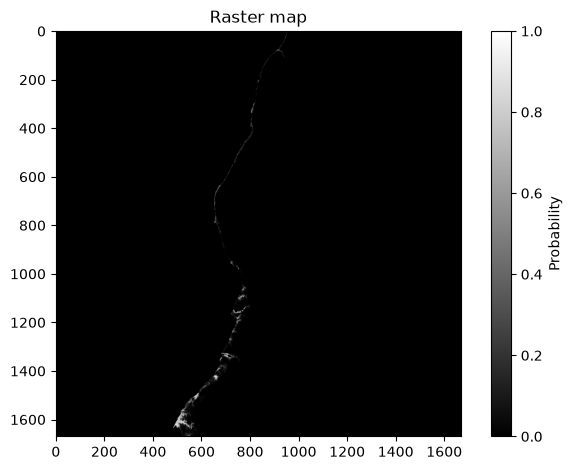

In [3]:
# map path
map_tile_9 = "../data/Delta_ClassProbability_tile_9.tif"
probability_map, _ = read_tif(map_tile_9)

# plot map if ypu want

# plot_tif(map_tile_9)
plot_numpy_raster(probability_map)

### 3. Find contour lines 

Selected contour points: 1299


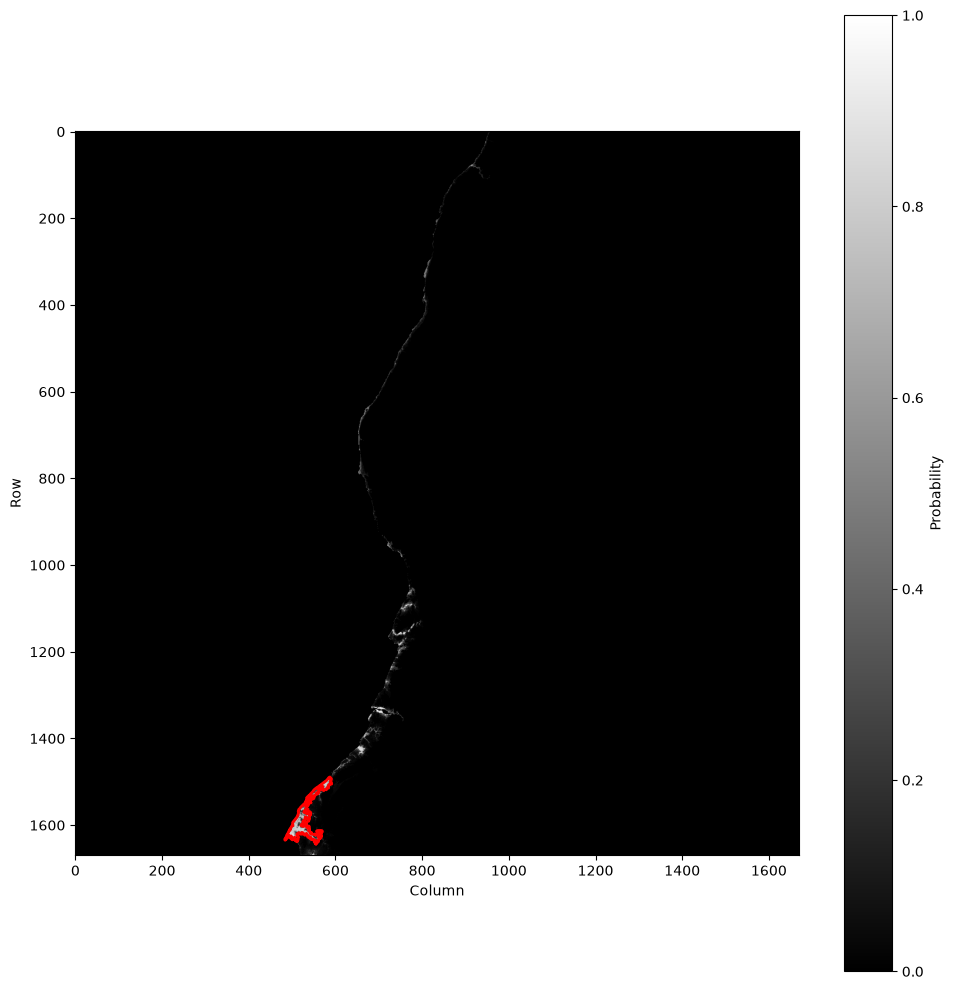

In [4]:
# Find contours

contours = contourline_segmentation(raster=probability_map, level=0.1)

# plot large contour if you want
plot_largest_contour(probability_map, contours)

# Filter nested contourlines and smaller area ones

20


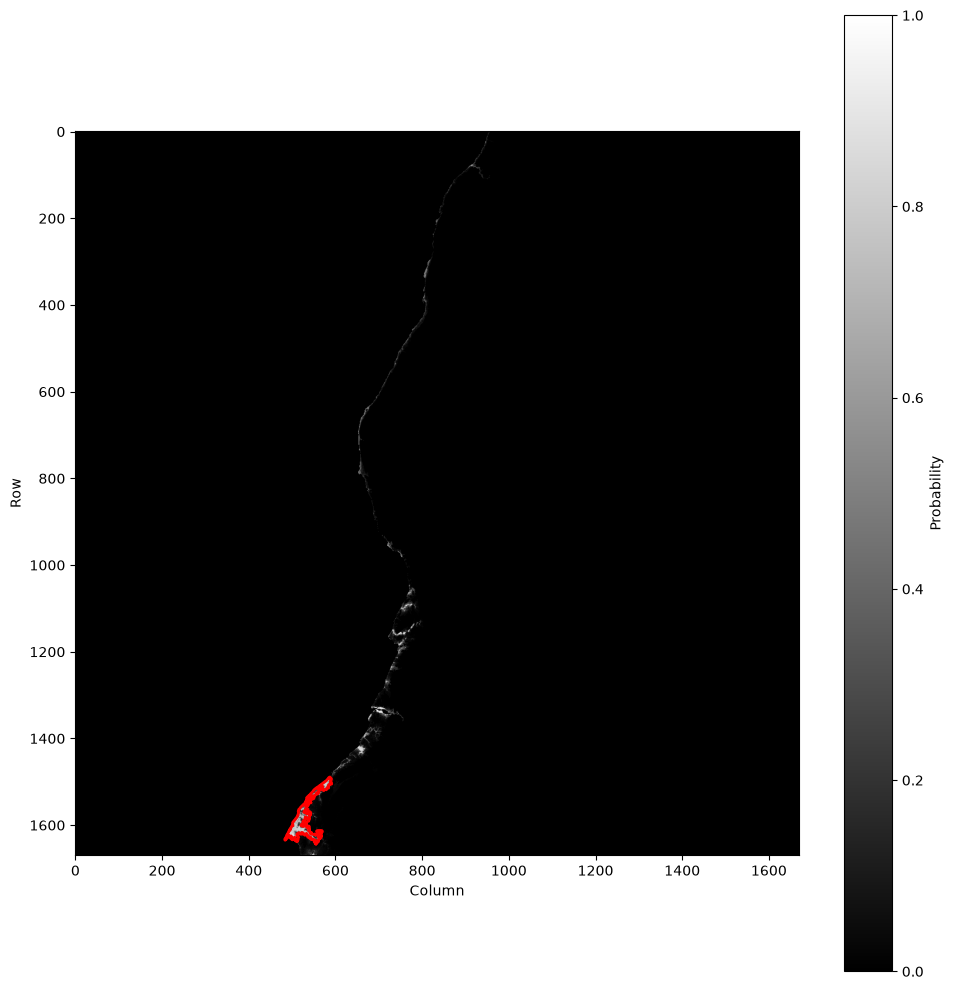

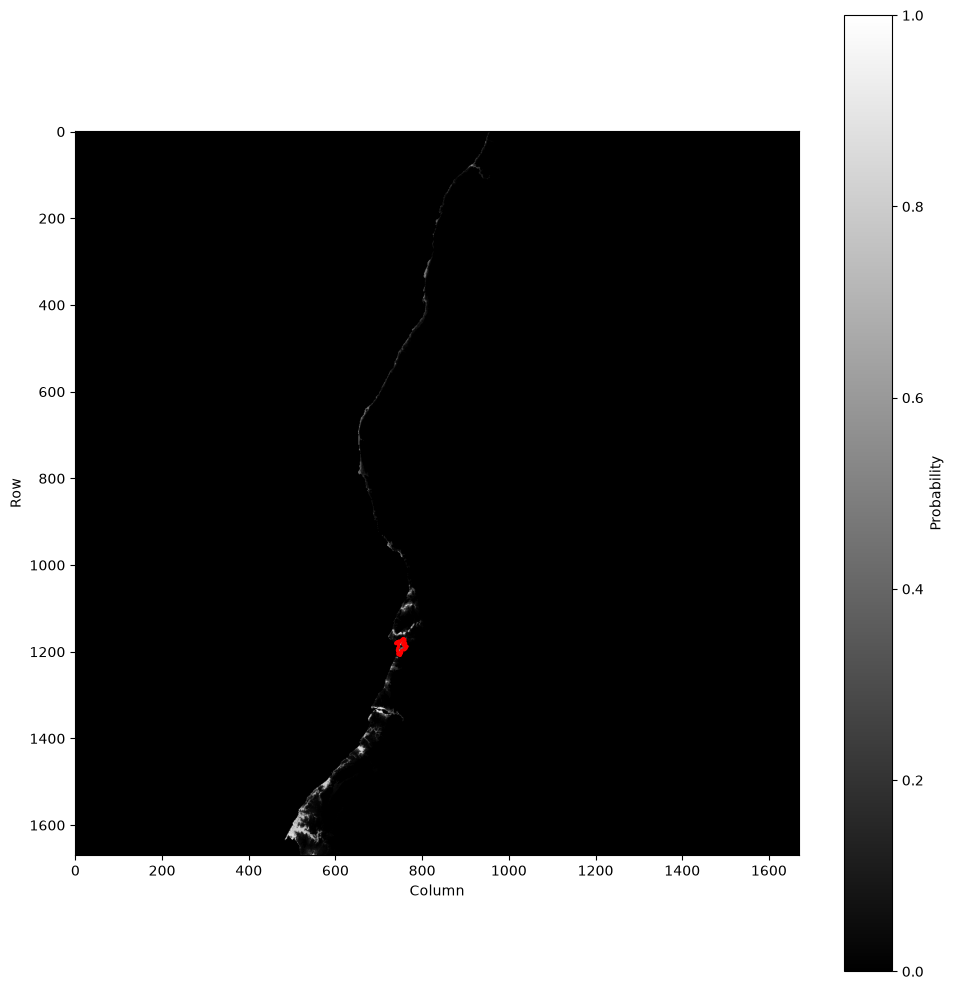

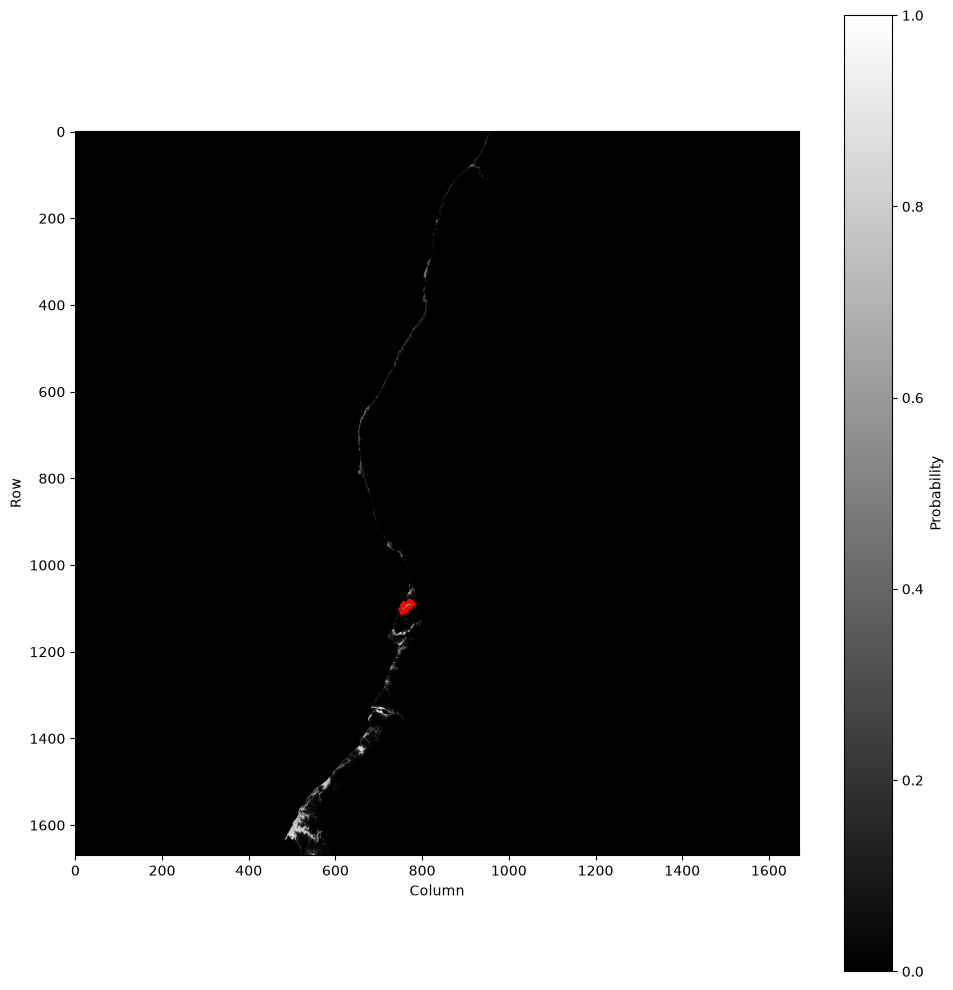

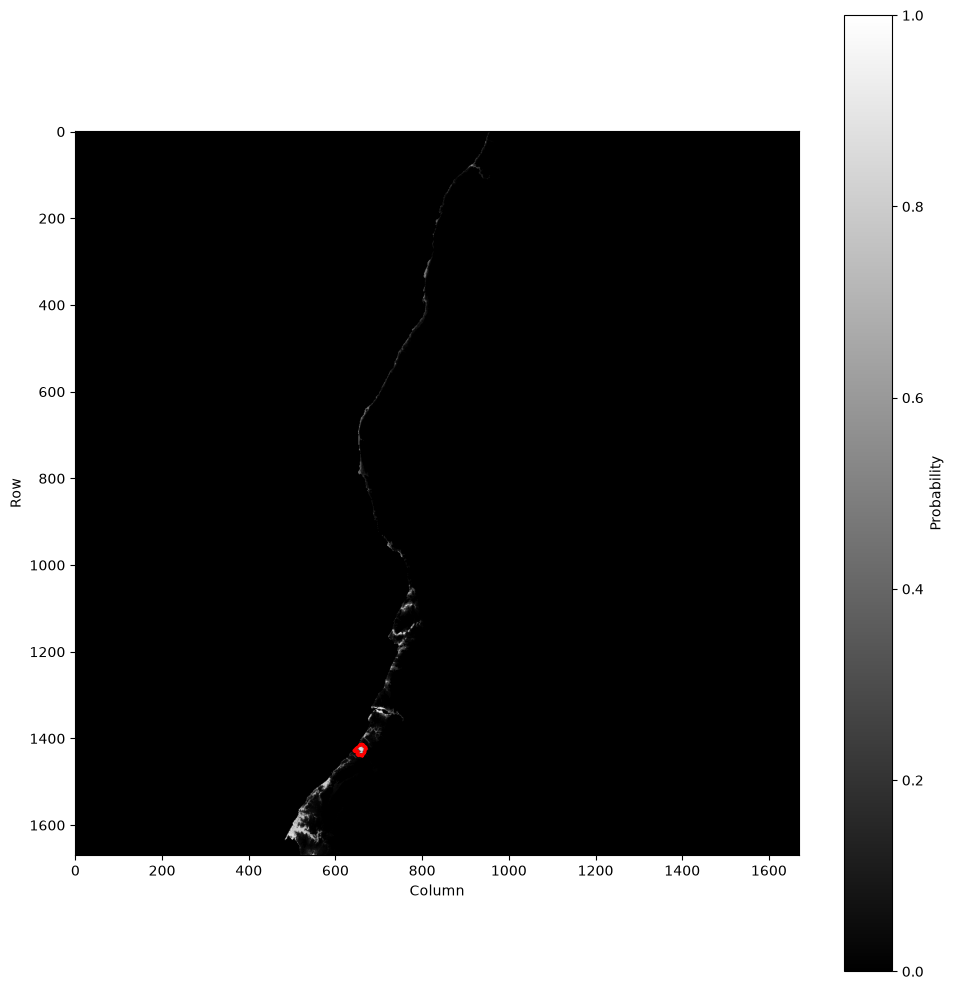

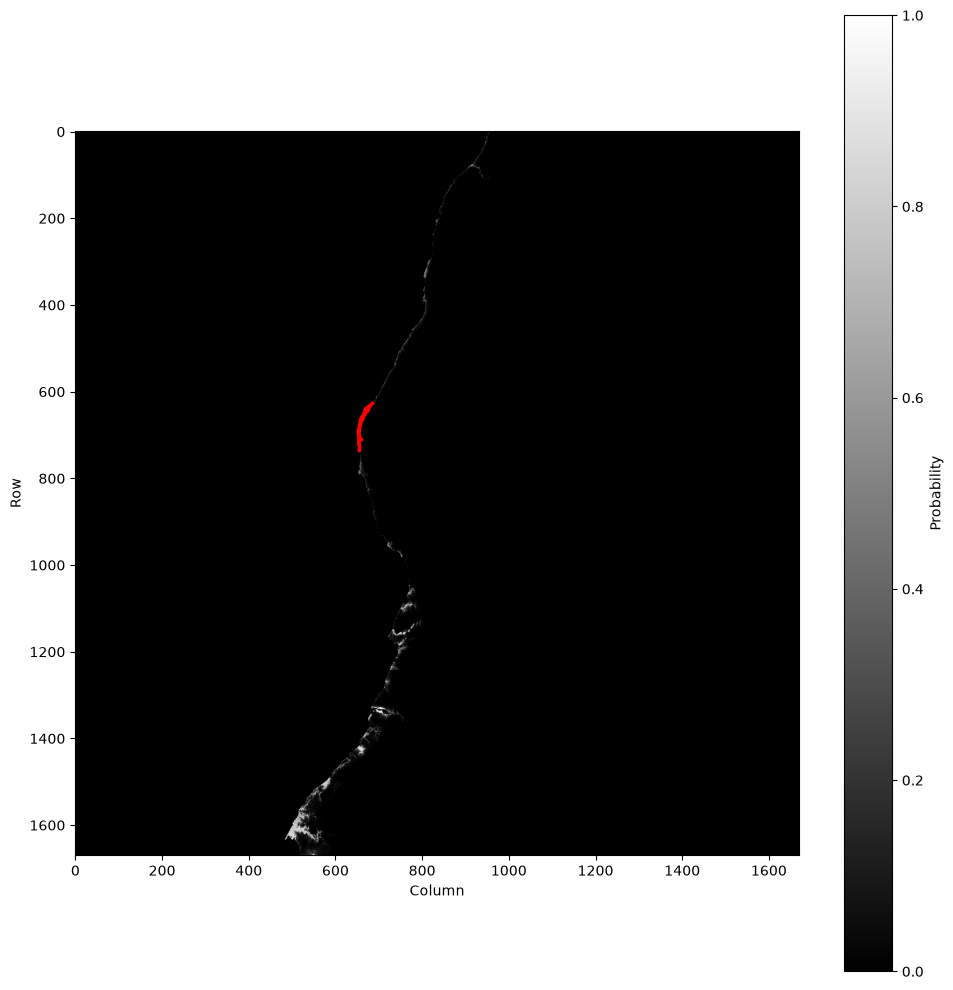

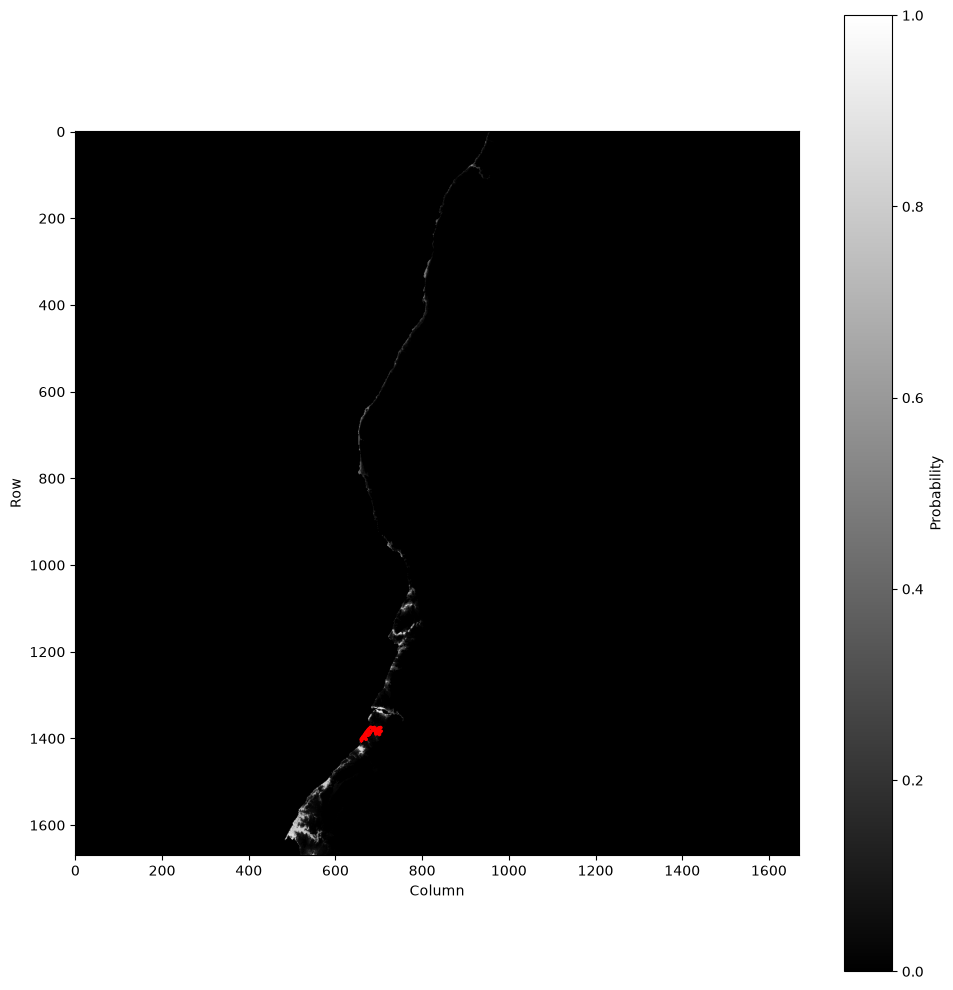

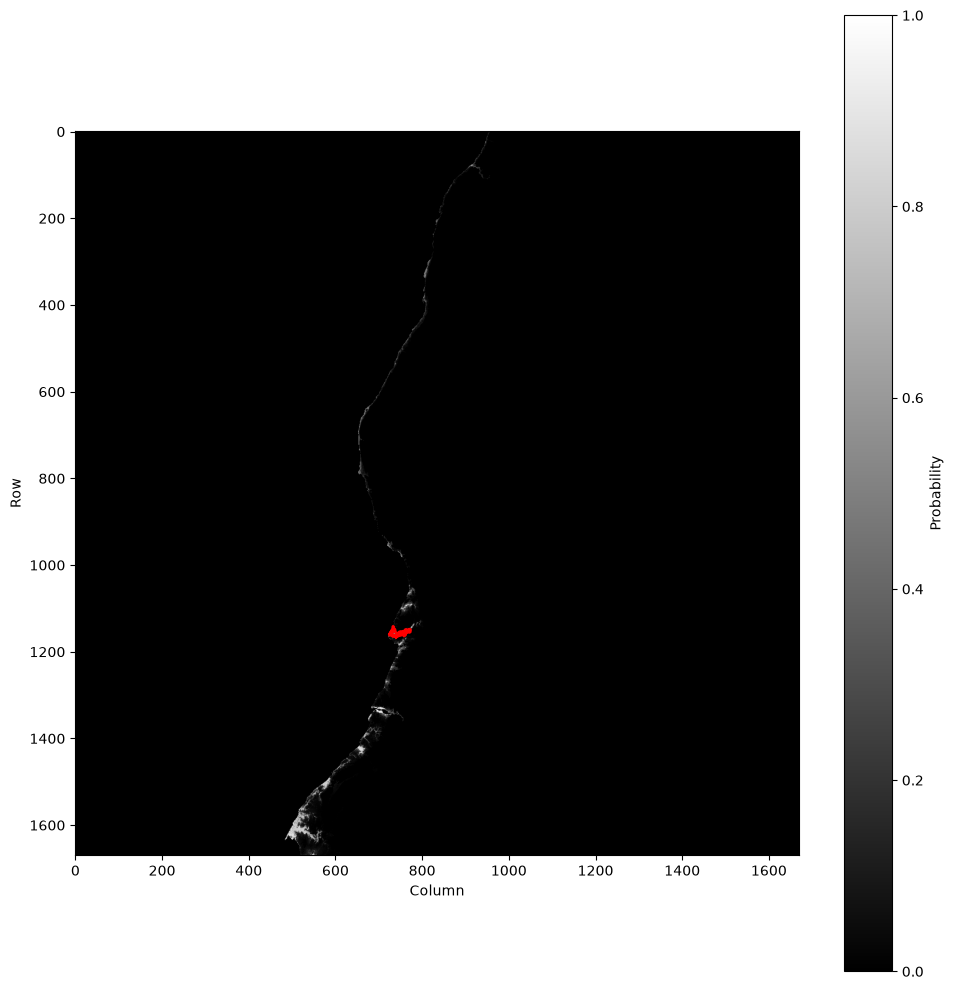

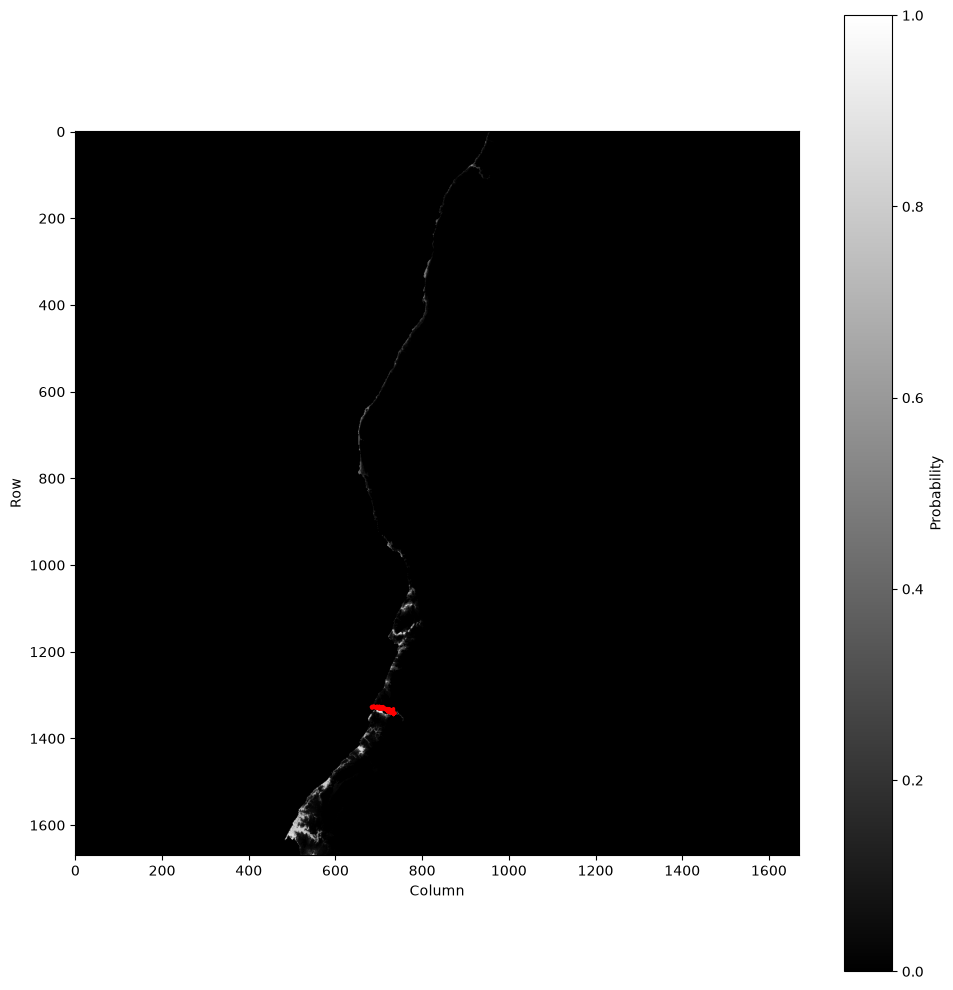

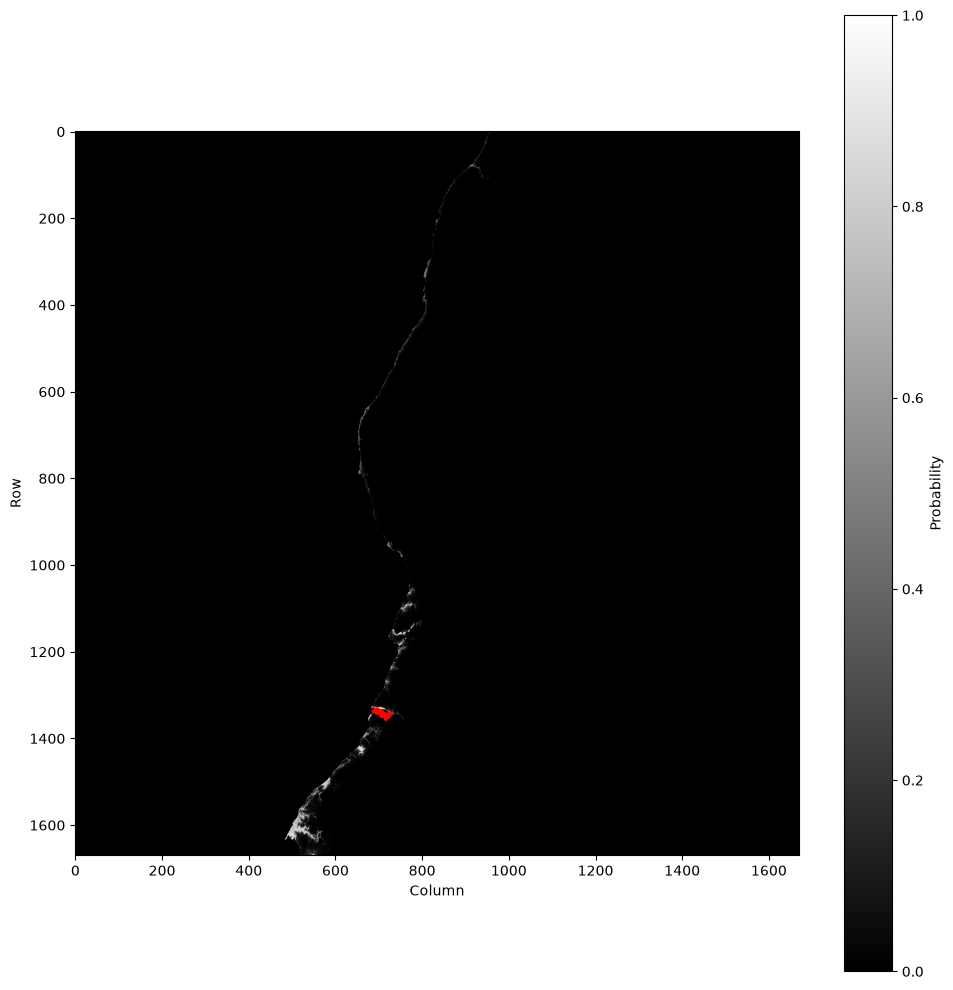

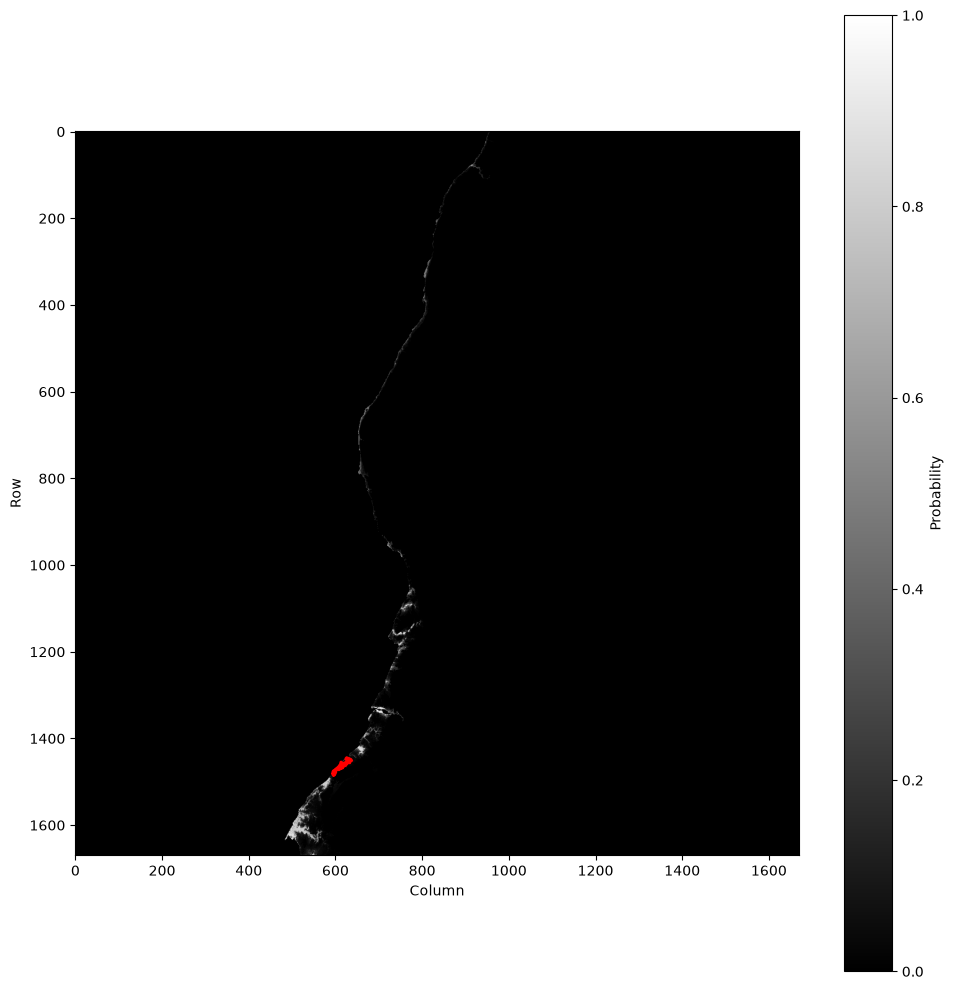

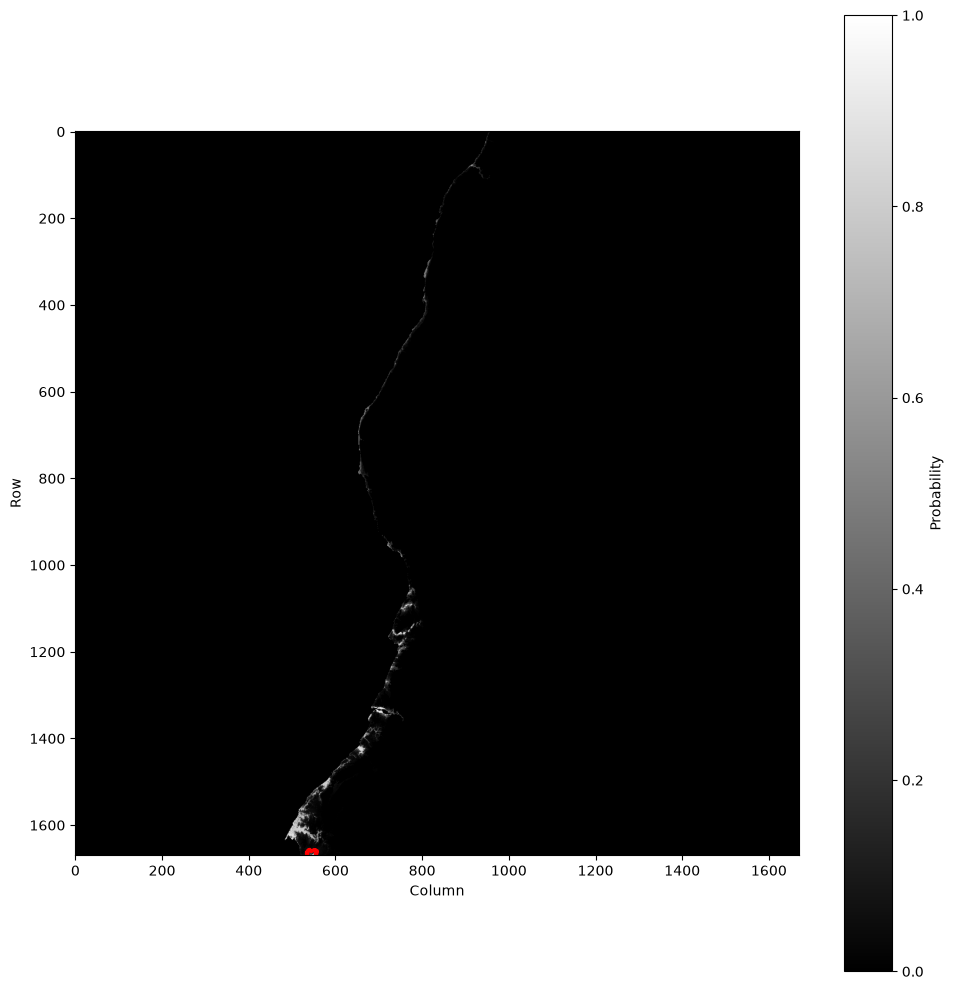

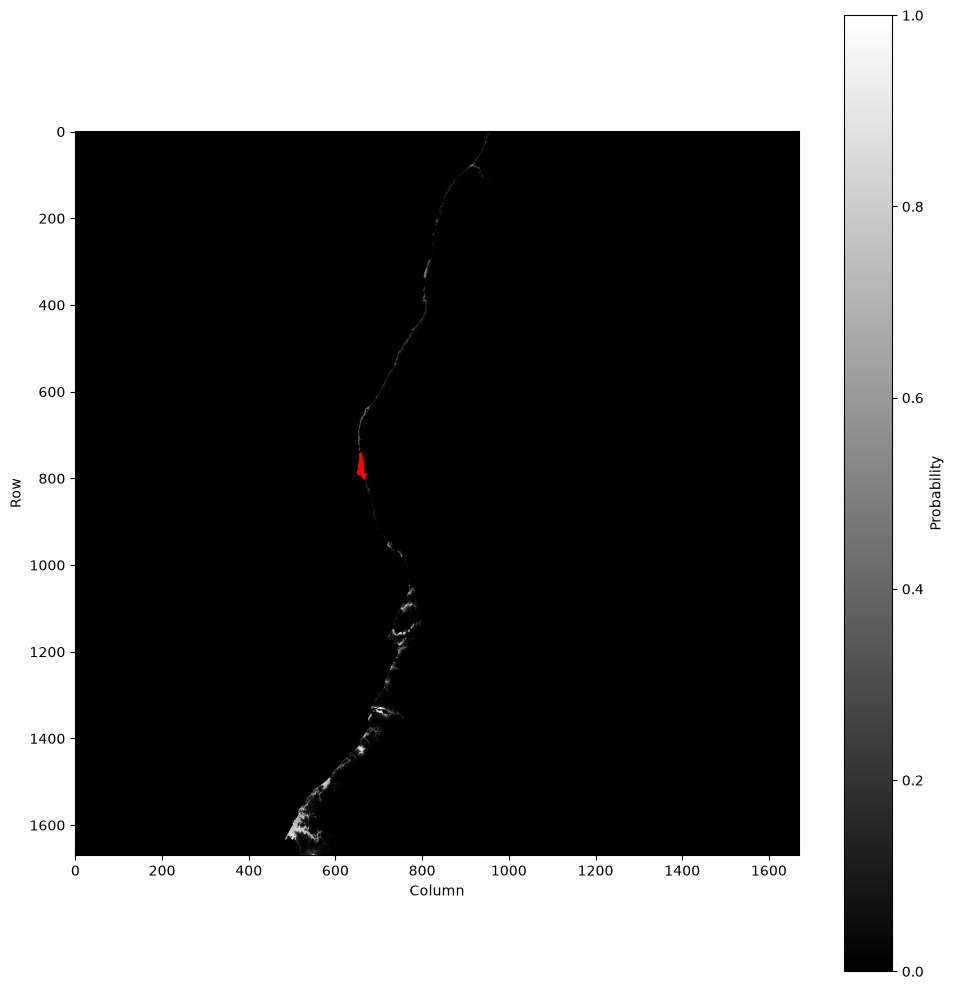

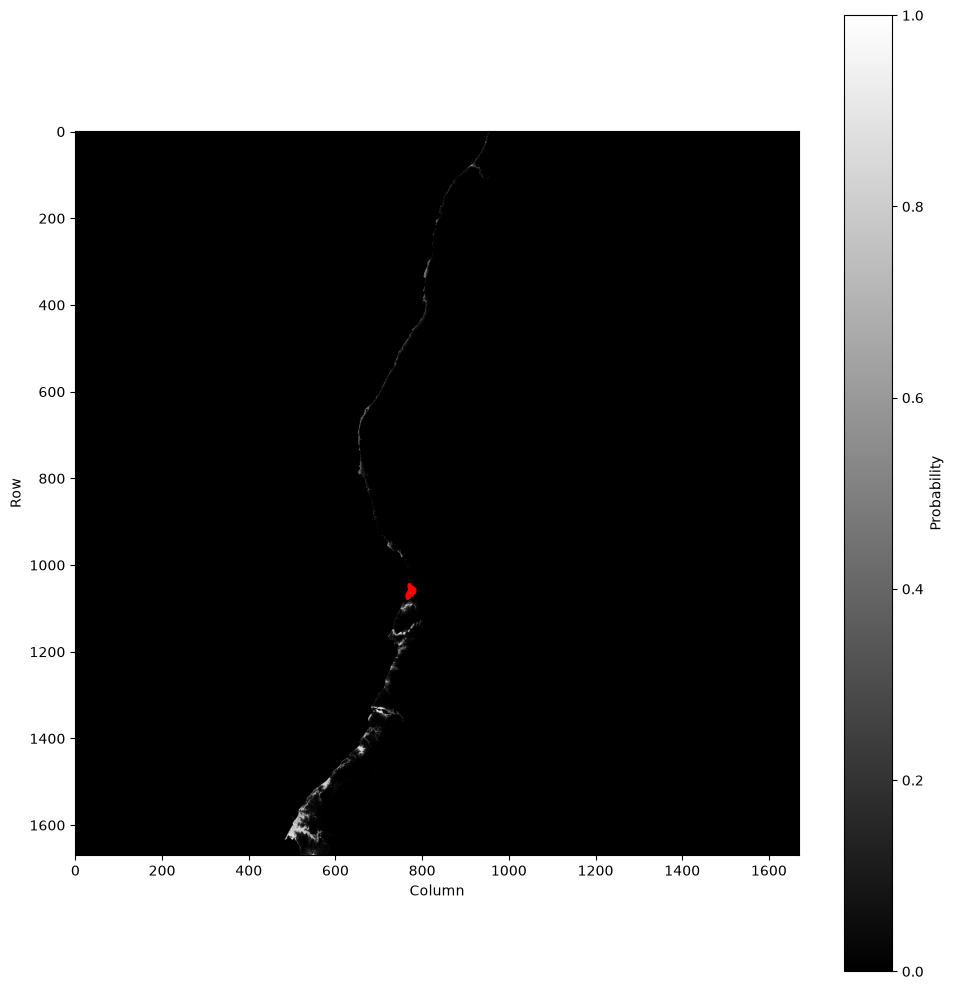

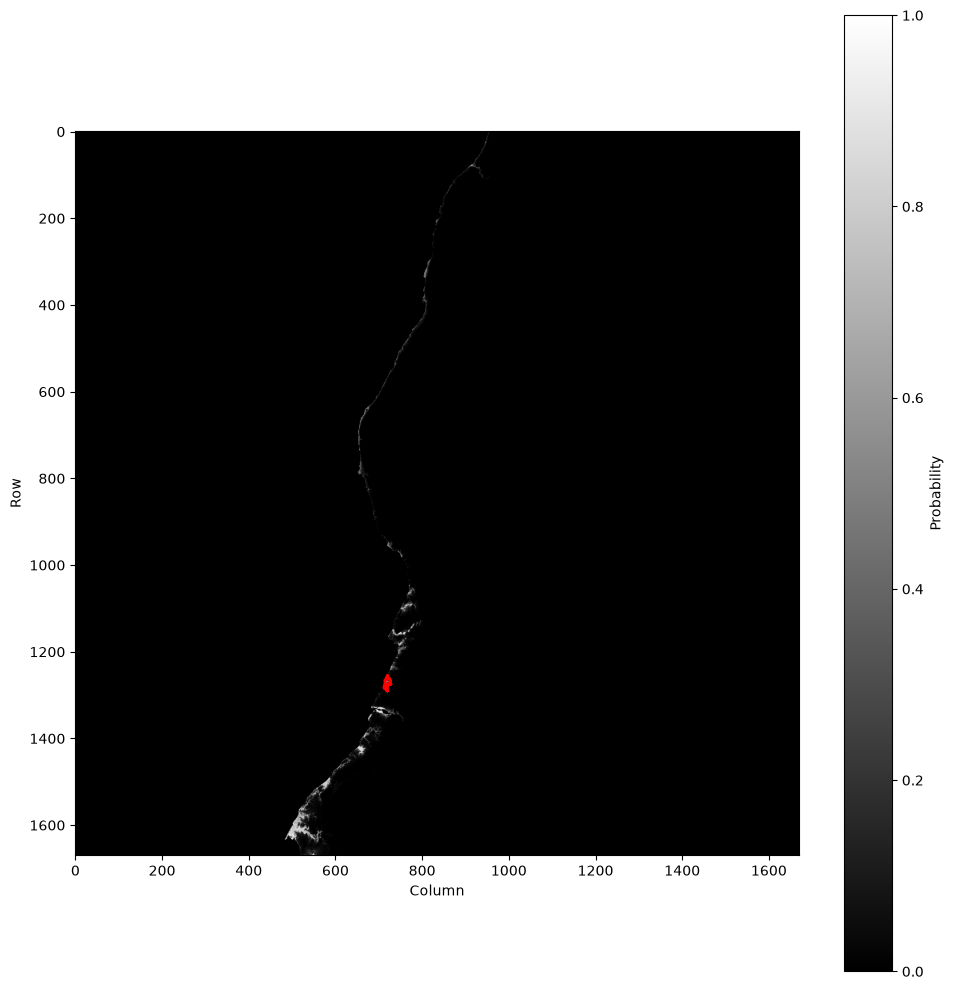

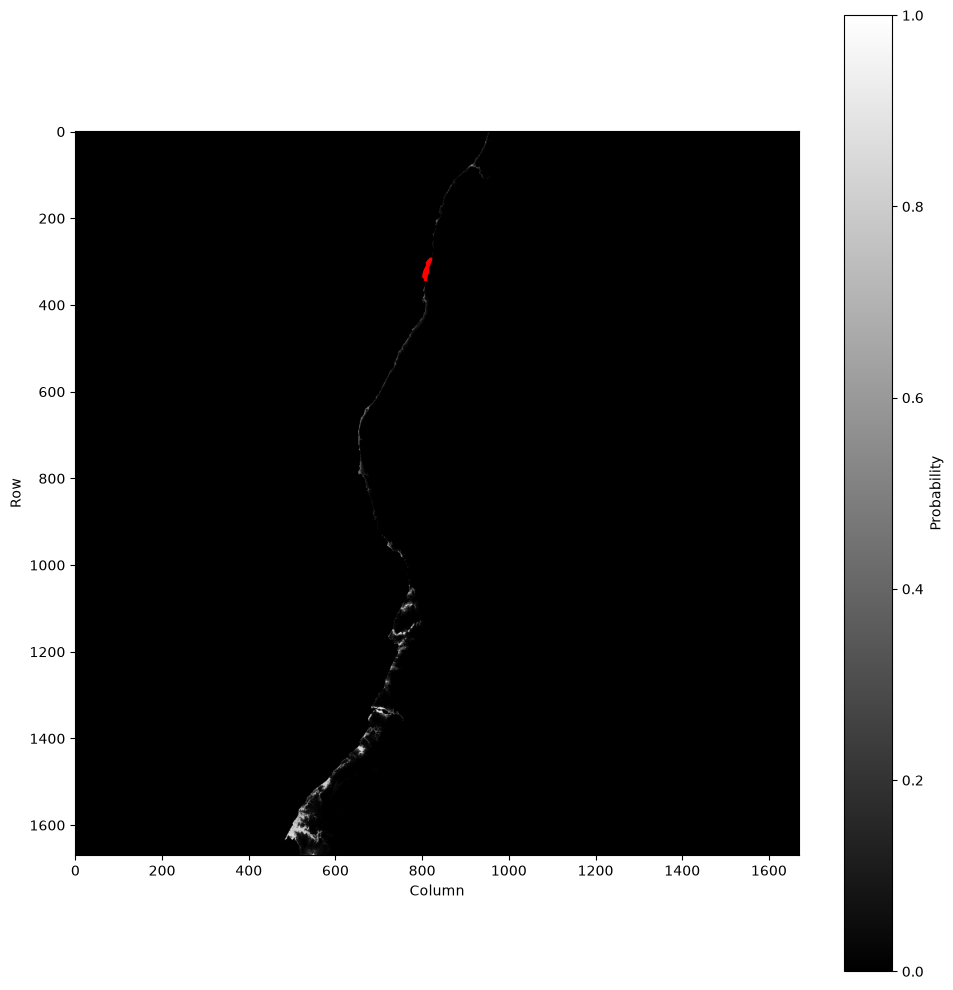

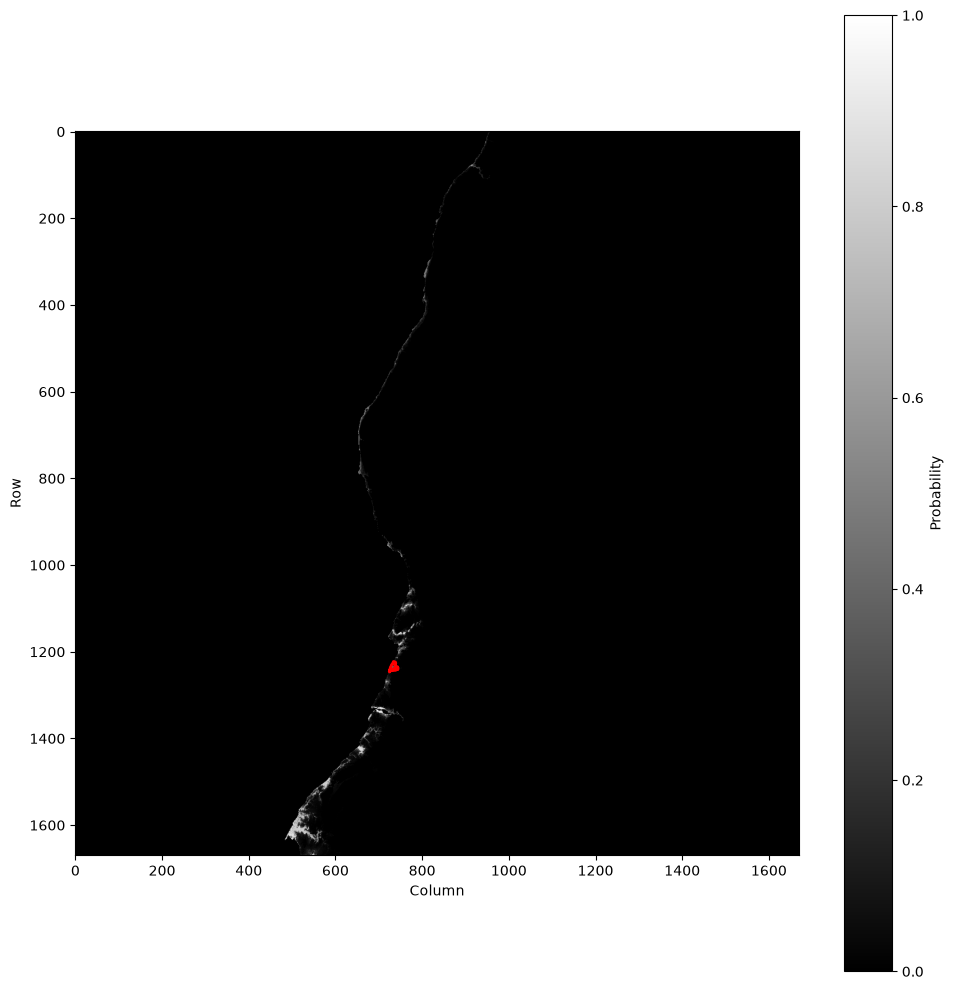

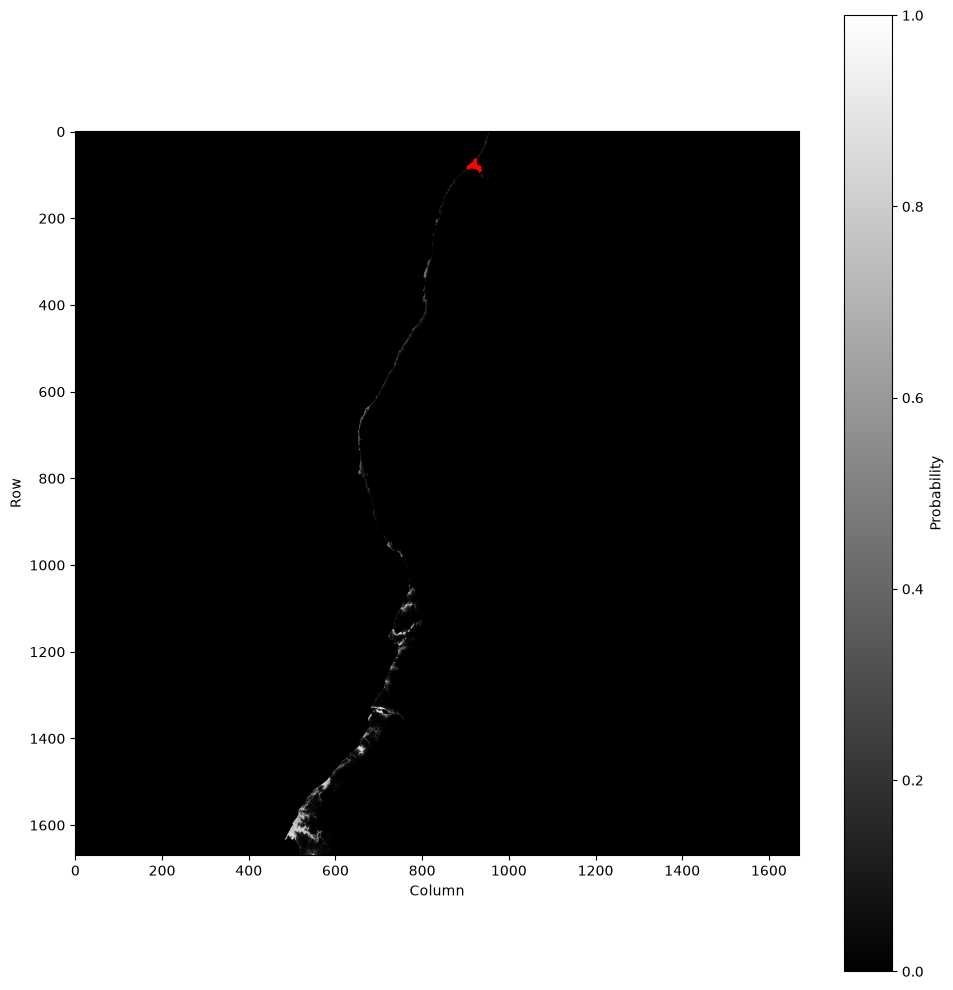

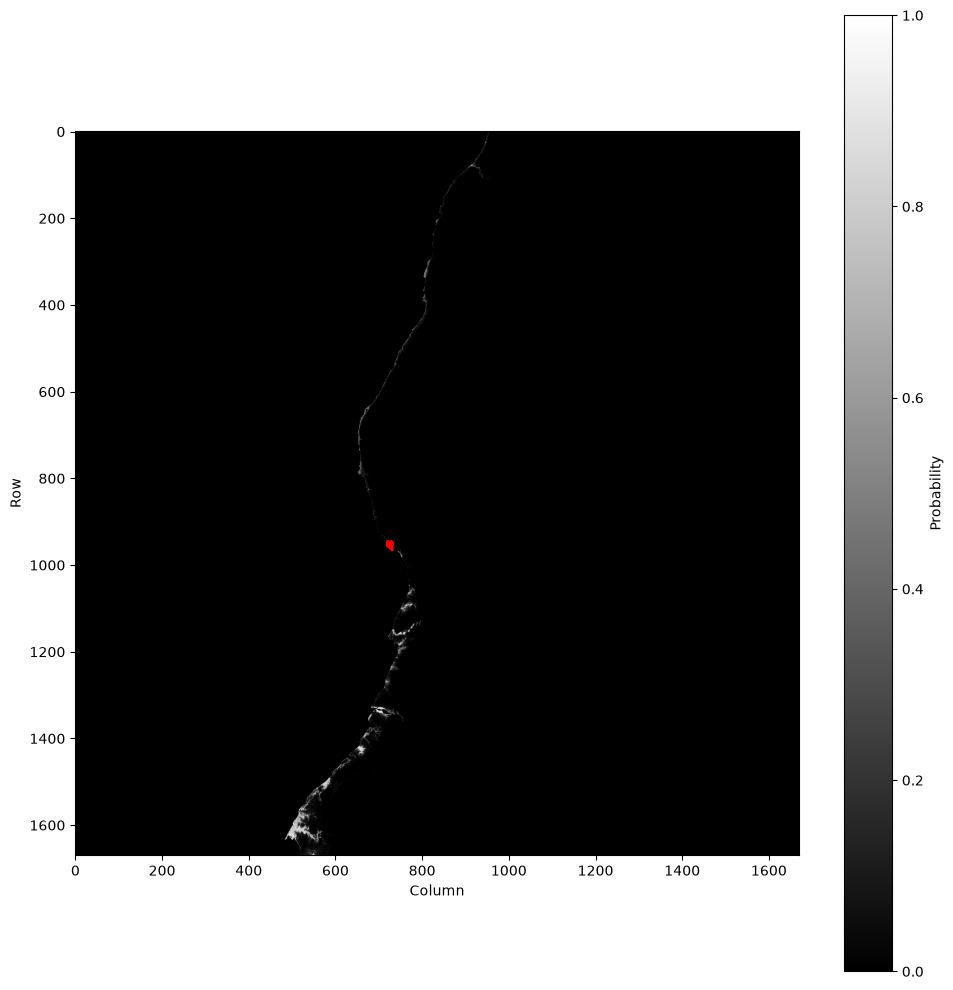

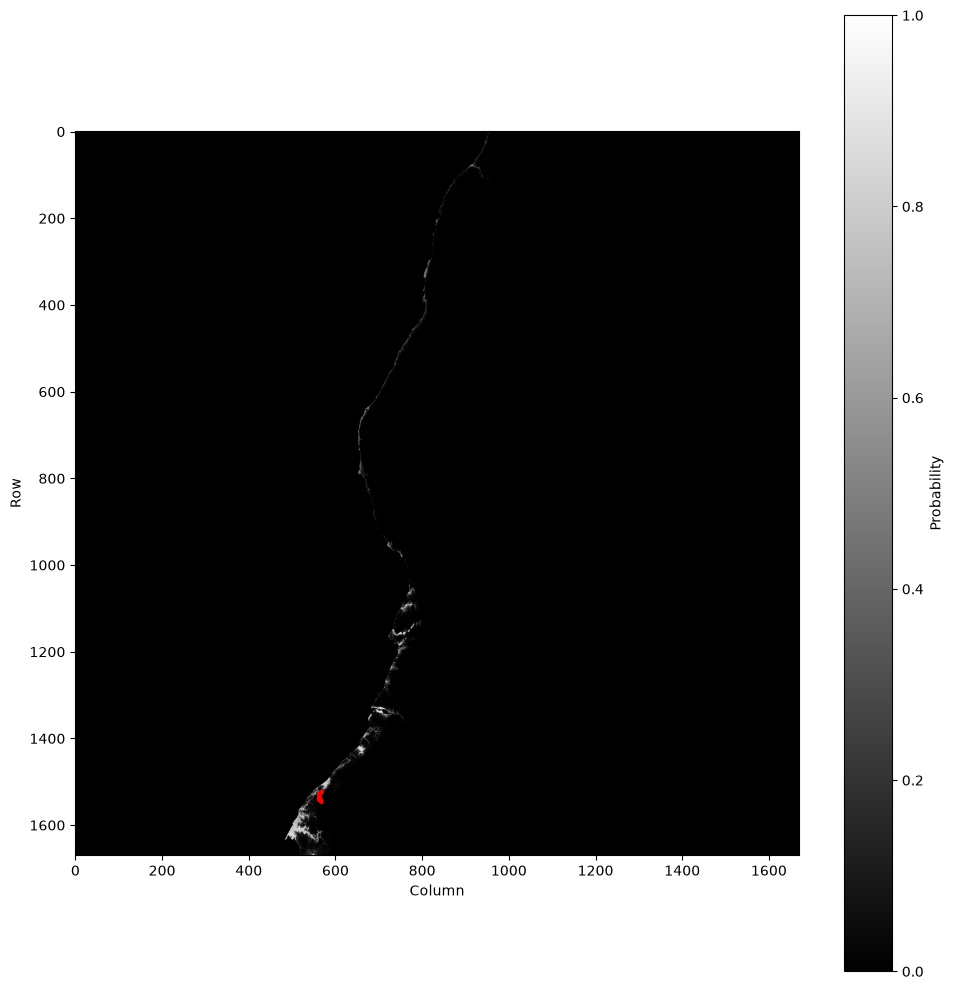

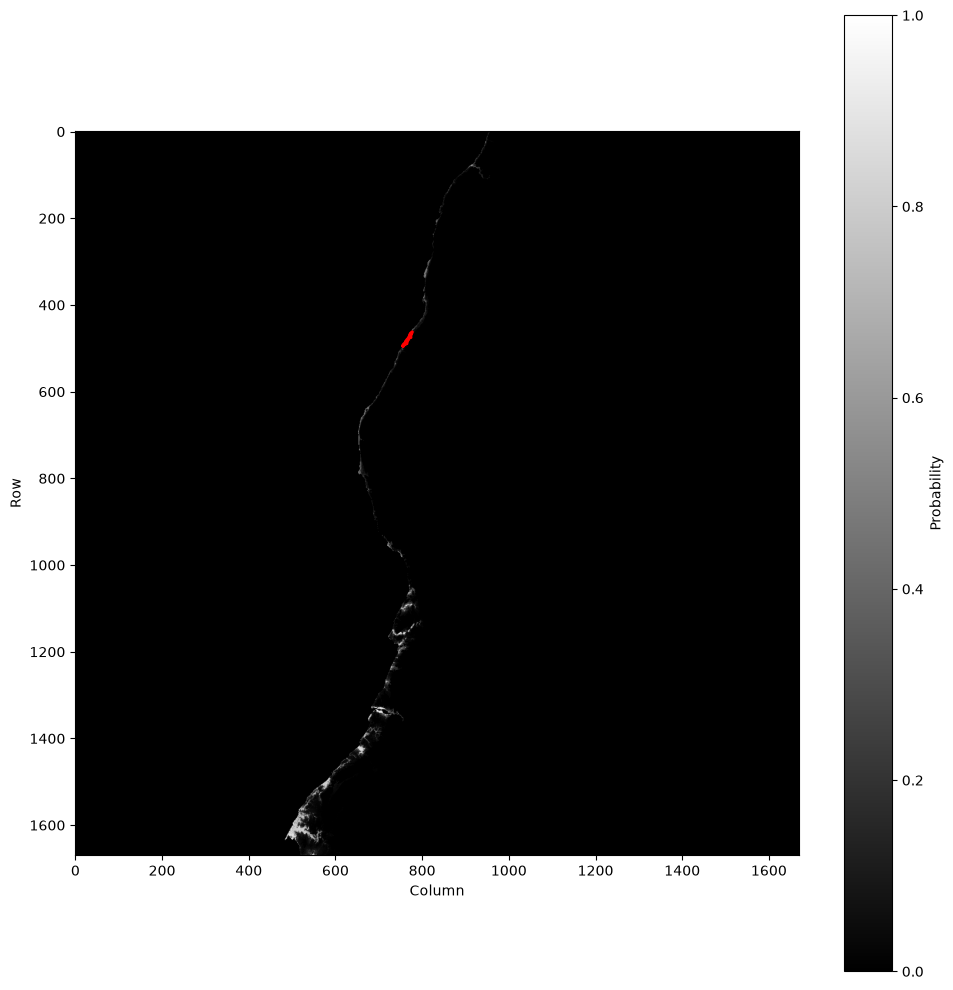

In [5]:
from lib.filter_image import filter_nested_and_small_contours

selected_contours = filter_nested_and_small_contours(contours)

print(len(selected_contours))

for i in range(len(selected_contours)):
    plot_contour(probability_map, selected_contours, i)